# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> YMLS Uzbekistan, ML Fundamentals, fall 2026 <a class="tocSkip">

# Week 7 seminar. Decision trees

A decision tree asks one question at a time. We grow a tree by hand on ten listings and check it against scikit-learn. On the flats of week 4 we watch the tree overfit as it gets deeper and choose the depth by cross-validation. A regression tree is fitted to the price curve of week 3. On the fake listings of week 5 a tree is compared with logistic regression and kNN. The last section resamples the data to see how much a tree changes. Section 6 is a bonus: a tree written from scratch.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/girafe-ai/ml-course/blob/26f_ymls_uz/week0_07_decision_trees/week0_07_01_decision_trees__completed.ipynb)

This week's [lecture slides](https://github.com/girafe-ai/ml-course/blob/26f_ymls_uz/week0_07_decision_trees/ml-basic_lect07_decision_trees.pdf) are in the same folder. The links to the interactive pages are in the course chat.

_YMLS Uzbekistan, ML Fundamentals, fall 2026_

_Completed version with solutions and outputs. The student version is `week0_07_01_decision_trees.ipynb`._

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    export_text,
    plot_tree,
)


# the same five stratified folds for every cross-validation in this notebook
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def rmse(prediction, target):
    """Root mean squared error."""
    return float(np.sqrt(np.mean((np.asarray(prediction) - np.asarray(target)) ** 2)))


def confusion(y, flagged):
    """TP, FP, FN, TN for the labels y (1 is the positive class) and the flags of a model."""
    y, flagged = np.asarray(y).astype(bool), np.asarray(flagged).astype(bool)
    tp, fp = int((flagged & y).sum()), int((flagged & ~y).sum())
    fn, tn = int((~flagged & y).sum()), int((~flagged & ~y).sum())
    return tp, fp, fn, tn


# Plot style: gray axes, colour only for data
INK, INK2, INK3, LINE = "#1D1D1F", "#6E6E73", "#86868B", "#D2D2D7"
ACCENT, ORANGE, GREEN, PURPLE = "#0071E3", "#FF9F0A", "#34C759", "#AF52DE"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 13,
        "mathtext.fontset": "cm",
        "axes.edgecolor": LINE,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.prop_cycle": plt.cycler(color=[ACCENT, ORANGE, GREEN, PURPLE, INK3]),
        "xtick.color": INK3,
        "ytick.color": INK3,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.minor.size": 0,
        "ytick.minor.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 11,
        "lines.linewidth": 2.2,
        "lines.markersize": 6,
        "figure.facecolor": "white",
    }
)
# shading for a share between 0 and 1: orange near 0, white at 0.5, blue near 1
SHARE_CMAP = LinearSegmentedColormap.from_list("share", [ORANGE, "white", ACCENT])

The helpers above come from earlier weeks: the RMSE of week 2, the stratified folds of week 3 and the four counts of the confusion matrix of week 5. Everywhere in this notebook class 1 is "fake" (or "sold") and class 0 is "real" (or "not sold").

## 1. Ten listings by hand

Here are ten listings from a site where some listings are fakes. Each has a markup (the asking price against the market estimate, in percent), a flag for a seller who asks for a prepayment and a flag for an account younger than three months.

In [2]:
HAND_FEATURES = ["markup", "prepayment", "new_account"]
hand = np.array(  # markup in %, asks for a prepayment, new account, fake
    [
        [-25, 1, 1, 1],
        [-18, 1, 0, 1],
        [-15, 1, 1, 1],
        [-14, 0, 0, 0],
        [-12, 1, 1, 1],
        [-3, 0, 1, 0],
        [0, 1, 0, 0],
        [4, 0, 0, 0],
        [8, 1, 1, 0],
        [15, 0, 0, 0],
    ]
)
X_hand, y_hand = hand[:, :3].astype(float), hand[:, 3]

print(" #   markup, %   asks for a prepayment   new account   label")
for number, (markup, prepayment, new, fake) in enumerate(hand, start=1):
    print(
        f"{number:2d} {markup:11d}   {'yes' if prepayment else 'no':>21s}   "
        f"{'yes' if new else 'no':>11s}   {'fake' if fake else 'real'}"
    )
print(f"\n{np.sum(y_hand == 1)} fake, {np.sum(y_hand == 0)} real")

 #   markup, %   asks for a prepayment   new account   label
 1         -25                     yes           yes   fake
 2         -18                     yes            no   fake
 3         -15                     yes           yes   fake
 4         -14                      no            no   real
 5         -12                     yes           yes   fake
 6          -3                      no           yes   real
 7           0                     yes            no   real
 8           4                      no            no   real
 9           8                     yes           yes   real
10          15                      no            no   real

4 fake, 6 real


A tree splits the listings into groups with questions of the form "feature $\le$ threshold". A good question leaves groups that are almost one class, and the Gini impurity measures how far a group is from that. Let $p_k$ be the share of class $k$ in the group. Pick a listing from the group at random, put it back and pick again. The Gini impurity is the chance that the two picks have different labels:

$$G = 1 - \sum_k p_k^2.$$

With two classes this is $2p(1 - p)$, where $p$ is the share of fakes. A group of one class has $G = 0$, and a group split half and half has $G = 0.5$.

**Exercise 1.1.** Write `gini(labels)`: the Gini impurity of a group, given the array of its class labels (0, 1, ...).

In [3]:
def gini(labels):
    """Gini impurity of a group: 1 minus the sum of the squared shares of the classes."""
    shares = np.bincount(labels) / len(labels)  # the share of every class in the group
    return 1 - np.sum(shares**2)

In [4]:
root_gini = gini(y_hand)
assert root_gini is not None, "Fill in gini above"
assert np.isclose(root_gini, 0.48), "Expect 0.48 for 4 fake and 6 real: 1 - 0.4**2 - 0.6**2"
assert np.isclose(gini(np.array([1, 1, 1, 1, 0])), 0.32), "Expect 0.32 for 4 fake and 1 real"
assert np.isclose(gini(np.array([0, 0, 0])), 0), "A group of one class has impurity 0"
assert np.isclose(
    gini(np.array([0, 1, 2])), 2 / 3
), "Expect 2/3 for three classes with one row each: sum the squares over all classes"


def entropy(labels):
    """Entropy of a group in bits: minus the sum of share * log2(share) over the classes."""
    shares = np.bincount(labels) / len(labels)
    shares = shares[shares > 0]  # a class that is absent adds nothing
    return 0.0 - np.sum(shares * np.log2(shares))


def error_rate(labels):
    """The share of the group that the majority answer gets wrong."""
    return 1 - np.bincount(labels).max() / len(labels)


print("group (fake, real)    Gini   entropy, bits   error rate")
for n_fake, n_real in [(4, 6), (4, 1), (5, 5), (0, 5)]:
    group = np.array([1] * n_fake + [0] * n_real)
    print(
        f"{n_fake:11d}, {n_real}     {gini(group):6.3f} {entropy(group):15.3f} "
        f"{error_rate(group):12.3f}"
    )

group (fake, real)    Gini   entropy, bits   error rate
          4, 6      0.480           0.971        0.400
          4, 1      0.320           0.722        0.200
          5, 5      0.500           1.000        0.500
          0, 5      0.000           0.000        0.000


The ten listings together have $G = 2 \times 0.4 \times 0.6 = 0.48$. The cell above also defines two other measures. Entropy is another impurity measure, counted in bits, and it is 0.971 here. The error rate is the share of the group that the majority answer gets wrong, 0.4. All three are 0 for a group of one class and largest at half and half. The page `02_impurity.html` draws the three curves.

A question "$x \le t$" sends the listings that answer yes to the left group and the rest to the right group. Its quality is the weighted impurity of the two groups,

$$\frac{n_L}{n} \, G_L + \frac{n_R}{n} \, G_R,$$

where $n_L$ and $n_R$ are the sizes of the groups. The gain of the question is the impurity before it minus this number.

**Exercise 1.2.** Write `split_impurity(x, y, t)`: the weighted impurity of the question `x <= t`, for a column of feature values `x` and the labels `y`.

In [5]:
def split_impurity(x, y, t, impurity=None):
    """Weighted impurity of the two groups made by the question x <= t (Gini by default)."""
    impurity = impurity or gini
    left, right = y[x <= t], y[x > t]  # the labels of the rows that answer yes and no
    return (len(left) * impurity(left) + len(right) * impurity(right)) / len(y)

In [6]:
assert gini(y_hand) is not None, "Finish Exercise 1.1 first"
QUESTIONS = [  # (the question, the column of X_hand, the threshold)
    ("markup <= -7.5", 0, -7.5),
    ("markup <= -14.5", 0, -14.5),
    ("markup <= -13", 0, -13.0),
    ("prepayment <= 0.5", 1, 0.5),
    ("new_account <= 0.5", 2, 0.5),
]
weighted = [split_impurity(X_hand[:, j], y_hand, t) for _, j, t in QUESTIONS]
assert weighted[0] is not None, "Fill in split_impurity above"
assert np.allclose(weighted, [0.16, 6 / 35, 19 / 60, 4 / 15, 0.40]), (
    "Expect 0.16, 0.171, 0.317, 0.267 and 0.40: weight the Gini of each group by its share "
    "of the ten listings"
)
print(
    f"{'question':19s} {'yes (fake, real)':>17s} {'no (fake, real)':>16s} {'weighted Gini':>14s} "
    f"{'gain':>6s} {'entropy gain':>13s} {'mistakes':>9s}"
)
for (name, j, t), after in zip(QUESTIONS, weighted, strict=True):
    yes, no = y_hand[X_hand[:, j] <= t], y_hand[X_hand[:, j] > t]
    entropy_gain = entropy(y_hand) - split_impurity(X_hand[:, j], y_hand, t, impurity=entropy)
    # every group answers with its majority class; count the listings it gets wrong
    mistakes = round(len(yes) * error_rate(yes) + len(no) * error_rate(no))
    print(
        f"{name:19s} {yes.sum():14d}, {len(yes) - yes.sum()} {no.sum():13d}, {len(no) - no.sum()} "
        f"{after:14.3f} {gini(y_hand) - after:6.3f} {entropy_gain:13.3f} {mistakes:9d}"
    )

question             yes (fake, real)  no (fake, real)  weighted Gini   gain  entropy gain  mistakes
markup <= -7.5                   4, 1             0, 5          0.160  0.320         0.610         1
markup <= -14.5                  3, 0             1, 6          0.171  0.309         0.557         1
markup <= -13                    3, 1             1, 5          0.317  0.163         0.256         2
prepayment <= 0.5                0, 4             4, 2          0.267  0.213         0.420         2
new_account <= 0.5               1, 4             3, 2          0.400  0.080         0.125         3


The yes/no features are coded 1 and 0, so their only possible threshold is 0.5, and the answer yes to "prepayment $\le 0.5$" means that the seller does not ask for a prepayment. The best of the five questions is "markup $\le -7.5$": the weighted impurity falls from 0.48 to 0.16, a gain of 0.32. Entropy puts the five questions in the same order. The number of mistakes cannot tell the first two apart, since both leave one listing of ten in a group where it is the minority, and that is why trees are grown with Gini or entropy.

A tree is grown greedily. Try every feature and every threshold, keep the best question, then repeat inside each of the two groups. For a number such as the markup the thresholds worth trying are the midpoints between neighbouring values, because every threshold between the same two values splits the listings the same way.

**Exercise 1.3.** Write `best_split(X, y)`. It scans the columns of `X` in order and, for each column, every midpoint between neighbouring distinct values. It returns a tuple: the number of the column, the threshold and the weighted Gini impurity of the best question. A question replaces the best one so far only if it is strictly better.

In [7]:
def best_split(X, y):
    """The question with the smallest weighted Gini: (column, threshold, weighted impurity)."""
    best = None
    for j in range(X.shape[1]):  # the features in order
        values = np.unique(X[:, j])  # the sorted distinct values of feature j
        for t in (values[:-1] + values[1:]) / 2:  # the midpoints between neighbours
            weighted = split_impurity(X[:, j], y, t)
            if best is None or weighted < best[2] - 1e-12:  # strictly better
                best = (j, float(t), float(weighted))
    return best

best question: markup <= -7.5, weighted Gini 0.16
11 questions tried, 9 of them about the markup
markup <=       -21.5  -16.5  -14.5    -13   -7.5   -1.5      2      6   11.5
weighted Gini   0.400  0.300  0.171  0.317  0.160  0.267  0.343  0.400  0.444


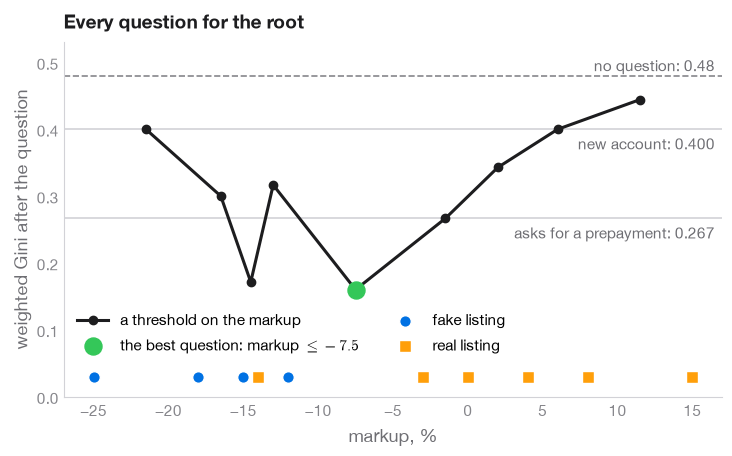

In [8]:
assert split_impurity(X_hand[:, 0], y_hand, -7.5) is not None, "Finish Exercise 1.2 first"
root_split = best_split(X_hand, y_hand)
assert root_split is not None, "Fill in best_split above"
assert root_split[0] == 0 and np.isclose(root_split[1], -7.5), (
    "Expect column 0 (markup) and the threshold -7.5: the smallest weighted Gini over all "
    "columns and midpoints"
)
assert np.isclose(
    root_split[2], 0.16
), "The third element is the weighted Gini of the question, 0.16"
print(
    f"best question: {HAND_FEATURES[root_split[0]]} <= {root_split[1]}, "
    f"weighted Gini {root_split[2]:.2f}"
)

# every question the search tries: (column, threshold, weighted Gini)
tried = []
for j in range(X_hand.shape[1]):
    values = np.unique(X_hand[:, j])
    tried += [
        (j, t, split_impurity(X_hand[:, j], y_hand, t)) for t in (values[:-1] + values[1:]) / 2
    ]
markup_t = [t for j, t, _ in tried if j == 0]
markup_gini = [value for j, _, value in tried if j == 0]
print(f"{len(tried)} questions tried, {len(markup_t)} of them about the markup")
print("markup <=      " + " ".join(f"{t:6g}" for t in markup_t))
print("weighted Gini  " + " ".join(f"{value:6.3f}" for value in markup_gini))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.axhline(gini(y_hand), color=INK3, ls="--", lw=1.2)
ax.text(16.5, 0.487, "no question: 0.48", ha="right", fontsize=11, color=INK2)
for (_, _, value), name in zip(tried[-2:], ["asks for a prepayment", "new account"], strict=True):
    ax.axhline(value, color=LINE, lw=1.2)
    ax.text(16.5, value - 0.03, f"{name}: {value:.3f}", ha="right", fontsize=11, color=INK2)
ax.plot(markup_t, markup_gini, "o-", color=INK, label="a threshold on the markup")
ax.scatter(
    [root_split[1]],
    [root_split[2]],
    s=150,
    color=GREEN,
    zorder=4,
    label=f"the best question: markup $\\leq {root_split[1]}$",
)
for label, name, colour in [(1, "fake", ACCENT), (0, "real", ORANGE)]:
    ax.scatter(
        X_hand[y_hand == label, 0],
        np.full(np.sum(y_hand == label), 0.03),
        s=70,
        marker="o" if label else "s",
        color=colour,
        edgecolor="white",
        label=f"{name} listing",
    )
ax.set(
    xlabel="markup, %",
    ylabel="weighted Gini after the question",
    ylim=(0, 0.53),
    title="Every question for the root",
)
ax.legend(loc="lower left", bbox_to_anchor=(0, 0.08), ncols=2)
plt.show()

The search tries 11 questions: nine thresholds on the markup and one for each yes/no feature. "markup $\le -7.5$" wins with 0.16, just ahead of "markup $\le -14.5$" with 0.171. Now the same search runs inside each of the two groups.

In [9]:
assert best_split(X_hand, y_hand) is not None, "Finish Exercise 1.3 first"
cheap = X_hand[:, 0] <= -7.5  # the listings that answer yes at the root
for name, group in [("yes", cheap), ("no", ~cheap)]:
    labels = y_hand[group]
    print(
        f"markup <= -7.5, {name}: {labels.sum()} fake, {np.sum(labels == 0)} real, "
        f"Gini {gini(labels):.2f}"
    )
    if gini(labels) > 0:
        j, t, after = best_split(X_hand[group], labels)
        print(f"    best question inside: {HAND_FEATURES[j]} <= {t}, weighted Gini {after:.2f}")

markup <= -7.5, yes: 4 fake, 1 real, Gini 0.32
    best question inside: prepayment <= 0.5, weighted Gini 0.00
markup <= -7.5, no: 0 fake, 5 real, Gini 0.00


The yes group has 4 fakes and 1 real listing. The question "prepayment $\le 0.5$" splits it into two groups of one class: the one seller who does not ask for a prepayment is real, and the four who ask are fakes. The no group has five real listings and needs no question. A group that is not split any further is a leaf. The finished tree has depth 2 and three leaves, and it gets all ten listings right. The page `01_grow_a_tree.html` lets you grow it by hand.

scikit-learn grows a tree with the same kind of search. A new listing arrives: a markup of $-10$, no prepayment asked, a new account.

**Exercise 1.4.** Fit `DecisionTreeClassifier(random_state=0)` on `X_hand`, `y_hand` as `hand_tree`. Store its prediction for `new_listing` in `new_label` (`predict` returns an array with one label per row).

In [10]:
new_listing = np.array([[-10, 0, 1]])  # markup, asks for a prepayment, new account
hand_tree = DecisionTreeClassifier(random_state=0).fit(X_hand, y_hand)
new_label = hand_tree.predict(new_listing)[0]

|--- markup <= -7.50
|   |--- prepayment <= 0.50
|   |   |--- class: 0
|   |--- prepayment >  0.50
|   |   |--- class: 1
|--- markup >  -7.50
|   |--- class: 0

right on 10 of the 10 listings
the new listing: real, P(fake) = 0.0


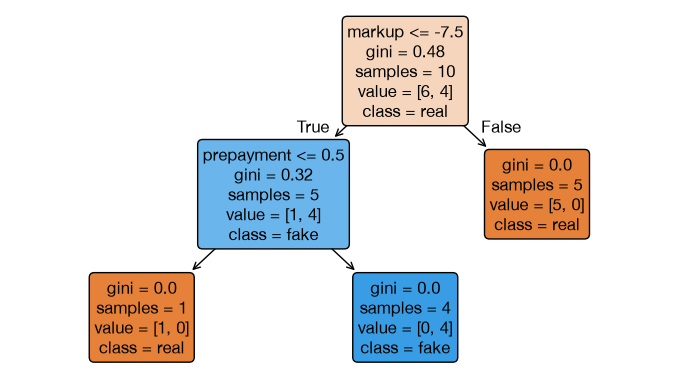

In [11]:
assert hand_tree is not None and new_label is not None, "Fill in hand_tree and new_label above"
assert isinstance(hand_tree, DecisionTreeClassifier), "hand_tree is a fitted DecisionTreeClassifier"
assert hand_tree.tree_.feature[0] == 0 and np.isclose(
    hand_tree.tree_.threshold[0], -7.5
), "Expect the root question markup <= -7.5: fit on X_hand, y_hand"
assert (
    hand_tree.get_depth() == 2 and hand_tree.get_n_leaves() == 3
), "Expect depth 2 and three leaves: leave max_depth at its default"
assert new_label == 0, "Expect 0 (real) for the new listing: hand_tree.predict(new_listing)[0]"
print(export_text(hand_tree, feature_names=HAND_FEATURES))
print(f"right on {np.sum(hand_tree.predict(X_hand) == y_hand)} of the 10 listings")
print(
    f"the new listing: {'fake' if new_label else 'real'}, "
    f"P(fake) = {hand_tree.predict_proba(new_listing)[0, 1]:.1f}"
)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
plot_tree(
    hand_tree,
    feature_names=HAND_FEATURES,
    class_names=["real", "fake"],
    filled=True,
    rounded=True,
    fontsize=12,
    ax=ax,
)
plt.show()

scikit-learn builds the same tree. `export_text` prints it as nested rules, and `plot_tree` draws it: every box shows the question, the Gini impurity of the group, the number of listings in it and how many of them are real and fake. To classify a listing, start at the top and follow the answers. The new listing answers yes at the root, since $-10 \le -7.5$, and yes to "prepayment $\le 0.5$", so it lands in the leaf with one real listing. A leaf answers with its majority class, and the share of fakes in the leaf is the predicted probability: 0 here.

## 2. Depth and overfitting

The data is the flats of week 4: 120 flats with an area in m² and a markup in percent, labelled by whether the flat sold. Mid-sized flats sell even with a markup, while very small and very large flats sell only at a discount. Another 400 flats from the same market play the part of new data.

In [12]:
FLAT_FEATURES = ["area", "markup"]


def area_sample(seed, n):
    """n flats: a matrix with the area in m² and the markup in percent, and sold (1) or not (0)."""
    rng = np.random.default_rng(seed)
    area = np.round(rng.uniform(30, 110, n), 0)
    markup = np.round(rng.uniform(-15, 25, n), 0)
    log_odds = 3.0 - 0.2 * markup - ((area - 65) / 14) ** 2
    sold = (rng.uniform(size=n) < 1 / (1 + np.exp(-log_odds))).astype(int)
    return np.column_stack([area, markup]), sold


X_flats, y_flats = area_sample(2, 120)  # the 120 flats we train on
X_flats_new, y_flats_new = area_sample(5002, 400)  # 400 new flats

# a fine grid over the plane, to colour it by the answer of a model
AREA_GRID, MARKUP_GRID = np.meshgrid(np.linspace(28, 112, 337), np.linspace(-17, 27, 177))
GRID = np.column_stack([AREA_GRID.ravel(), MARKUP_GRID.ravel()])


def scatter_sold(ax, X, y, size=20):
    """Flats on the plane: sold ones as blue circles, the others as orange squares."""
    style = {"s": size, "edgecolor": "white", "linewidth": 0.6, "zorder": 3}
    ax.scatter(*X[y == 1].T, color=ACCENT, label="sold", **style)
    ax.scatter(*X[y == 0].T, color=ORANGE, marker="s", label="not sold", **style)


def plot_regions(ax, model, title):
    """Colour the plane by the answer of the model and draw the 120 training flats on top."""
    answer = model.predict(GRID).reshape(AREA_GRID.shape)
    ax.contourf(
        AREA_GRID, MARKUP_GRID, answer, levels=[-0.5, 0.5, 1.5], colors=[ORANGE, ACCENT], alpha=0.22
    )
    scatter_sold(ax, X_flats, y_flats)
    ax.set(xlabel="area, m²", title=title)


print(f"{len(y_flats)} flats to train on, {y_flats.sum()} of them sold")
print(f"{len(y_flats_new)} new flats, {y_flats_new.mean():.0%} of them sold")

120 flats to train on, 52 of them sold
400 new flats, 45% of them sold


On this plane a question such as "markup $\le 8.5$" is a straight cut parallel to an axis, so a tree divides the plane into rectangles, one for each leaf. `max_depth` limits the number of questions between the root and a leaf.

**Exercise 2.1.** Fit three trees on the 120 flats, with `max_depth` equal to 1, 3 and `None` (no limit: the full tree), each as `DecisionTreeClassifier(max_depth=depth, random_state=0)`. Store them in the dictionary `flat_trees` under their depth.

In [13]:
flat_trees = {}
for depth in [1, 3, None]:
    flat_trees[depth] = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(
        X_flats, y_flats
    )

max_depth  leaves  accuracy, 120 flats  accuracy, 400 new flats
        1       2                0.767                    0.728
        3       6                0.933                    0.810
     full      22                1.000                    0.780

the first question: markup <= 8.5, Gini 0.491 before and 0.337 after

the tree of depth 3 (class 1 is sold):
|--- markup <= 8.50
|   |--- area <= 97.00
|   |   |--- area <= 38.00
|   |   |   |--- class: 0
|   |   |--- area >  38.00
|   |   |   |--- class: 1
|   |--- area >  97.00
|   |   |--- class: 0
|--- markup >  8.50
|   |--- area <= 78.00
|   |   |--- area <= 71.50
|   |   |   |--- class: 0
|   |   |--- area >  71.50
|   |   |   |--- class: 1
|   |--- area >  78.00
|   |   |--- class: 0



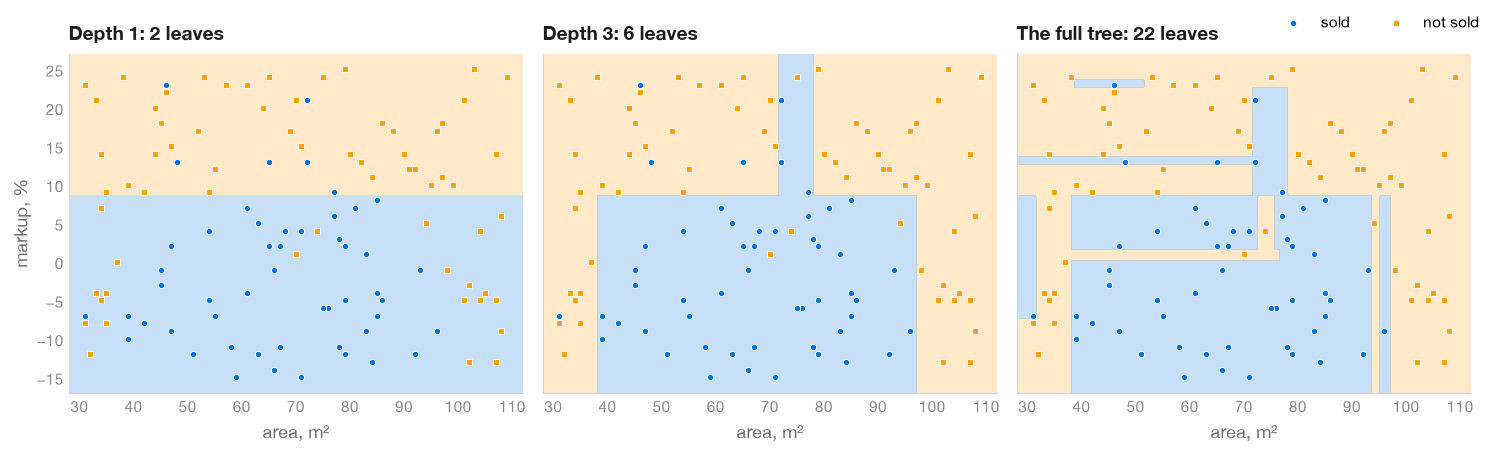

In [14]:
assert (
    len(flat_trees) == 3
), "Fill in the loop above: one fitted tree for each of the depths 1, 3 and None"
assert [flat_trees[depth].get_n_leaves() for depth in [1, 3, None]] == [
    2,
    6,
    22,
], "Expect 2, 6 and 22 leaves: max_depth=depth, random_state=0, fitted on X_flats, y_flats"
print(
    f"{'max_depth':>9s} {'leaves':>7s} {'accuracy, 120 flats':>20s} {'accuracy, 400 new flats':>24s}"
)
for depth, tree in flat_trees.items():
    print(
        f"{'full' if depth is None else depth:>9} {tree.get_n_leaves():7d} "
        f"{tree.score(X_flats, y_flats):20.3f} {tree.score(X_flats_new, y_flats_new):24.3f}"
    )
root = flat_trees[1].tree_  # the arrays of the fitted tree: node 0 is the root, 1 and 2 its groups
after = (
    root.n_node_samples[1] * root.impurity[1] + root.n_node_samples[2] * root.impurity[2]
) / 120
print(
    f"\nthe first question: {FLAT_FEATURES[root.feature[0]]} <= {root.threshold[0]}, "
    f"Gini {root.impurity[0]:.3f} before and {after:.3f} after"
)
print("\nthe tree of depth 3 (class 1 is sold):")
print(export_text(flat_trees[3], feature_names=FLAT_FEATURES))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (depth, tree) in zip(axes, flat_trees.items(), strict=True):
    name = "The full tree" if depth is None else f"Depth {depth}"
    plot_regions(ax, tree, f"{name}: {tree.get_n_leaves()} leaves")
axes[0].set_ylabel("markup, %")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2)
plt.show()

The tree of depth 1 asks one question, "markup $\le 8.5$", which lowers the Gini impurity from 0.491 to 0.337. Of the 68 flats that answer yes 46 sold, and of the other 52 only 6 sold. Depth 3 gives six rectangles and gets 0.933 of the training flats right. The full tree keeps cutting until every training flat is right. It needs 22 leaves, some of them a thin strip around a single flat, and on the 400 new flats it gets 0.780 where the tree of depth 3 gets 0.810.

**Exercise 2.2.** For every depth in `DEPTHS` fit a tree and append its accuracy on the 120 training flats to `train_acc` and its accuracy on the 400 new flats to `new_acc`. `tree.score(X, y)` is the accuracy.

In [15]:
DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8]
train_acc, new_acc = [], []
for depth in DEPTHS:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_flats, y_flats)
    train_acc.append(tree.score(X_flats, y_flats))
    new_acc.append(tree.score(X_flats_new, y_flats_new))

In [16]:
assert len(train_acc) == len(DEPTHS) and len(new_acc) == len(
    DEPTHS
), "Fill in the loop above: one number per depth in train_acc and in new_acc"
assert np.allclose(
    train_acc, [0.767, 0.858, 0.933, 0.942, 0.975, 0.975, 0.983, 1.0], atol=0.001
), "Expect 0.767 at depth 1 and 1.000 at depth 8 in train_acc: tree.score(X_flats, y_flats)"
assert np.allclose(
    new_acc, [0.728, 0.790, 0.810, 0.818, 0.805, 0.795, 0.795, 0.780], atol=0.001
), "Expect 0.728 at depth 1 and 0.780 at depth 8 in new_acc: tree.score(X_flats_new, y_flats_new)"
print(f"{'max_depth':>9s} {'accuracy, 120 flats':>20s} {'accuracy, 400 new flats':>24s}")
for depth, train, new in zip(DEPTHS, train_acc, new_acc, strict=True):
    print(f"{depth:9d} {train:20.3f} {new:24.3f}")

max_depth  accuracy, 120 flats  accuracy, 400 new flats
        1                0.767                    0.728
        2                0.858                    0.790
        3                0.933                    0.810
        4                0.942                    0.818
        5                0.975                    0.805
        6                0.975                    0.795
        7                0.983                    0.795
        8                1.000                    0.780


On the training flats the accuracy only grows with the depth, up to 1.000 at depth 8, where the tree is the full tree. On the new flats it is best at depth 4, with 0.818, and deeper trees do worse. This is the overfitting of week 3.

The 400 new flats play the part of a test set here, and a test set is opened once, so it cannot be used to choose the depth. The choice is made by cross-validation on the 120 training flats.

**Exercise 2.3.** Build `depth_search`: a `GridSearchCV` over `DecisionTreeClassifier(random_state=0)` with the grid `{"max_depth": DEPTHS}` and `cv=folds`, the five stratified folds from the setup. Fit it on the training flats. Store the mean validation accuracy of every depth in `cv_acc` (it is `depth_search.cv_results_["mean_test_score"]`) and the chosen depth in `best_depth` (`depth_search.best_params_["max_depth"]`).

In [17]:
depth_search = GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": DEPTHS}, cv=folds)
depth_search.fit(X_flats, y_flats)
cv_acc = depth_search.cv_results_["mean_test_score"]
best_depth = depth_search.best_params_["max_depth"]

max_depth  accuracy, 120 flats  cross-validation  accuracy, 400 new flats
        1                0.767             0.750                    0.728
        2                0.858             0.792                    0.790
        3                0.933             0.900                    0.810
        4                0.942             0.892                    0.818
        5                0.975             0.875                    0.805
        6                0.975             0.883                    0.795
        7                0.983             0.875                    0.795
        8                1.000             0.875                    0.780
depth chosen by cross-validation: 3


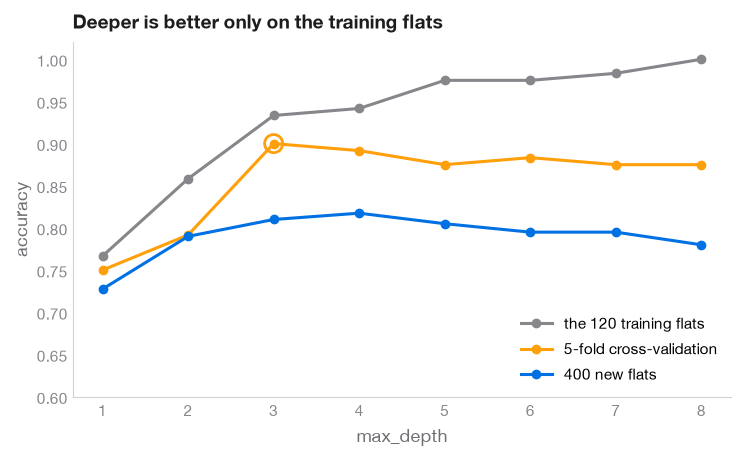

In [18]:
assert len(train_acc) == len(DEPTHS) and len(new_acc) == len(DEPTHS), "Finish Exercise 2.2 first"
assert (
    depth_search is not None and cv_acc is not None and best_depth is not None
), "Fill in depth_search, cv_acc and best_depth above"
assert np.allclose(
    cv_acc, [0.750, 0.792, 0.900, 0.892, 0.875, 0.883, 0.875, 0.875], atol=0.001
), "Expect 0.750 at depth 1 and 0.900 at depth 3: the grid is {'max_depth': DEPTHS}, cv=folds"
assert best_depth == 3, "Expect depth 3: depth_search.best_params_['max_depth']"
print(
    f"{'max_depth':>9s} {'accuracy, 120 flats':>20s} {'cross-validation':>17s} "
    f"{'accuracy, 400 new flats':>24s}"
)
for depth, train, cv, new in zip(DEPTHS, train_acc, cv_acc, new_acc, strict=True):
    print(f"{depth:9d} {train:20.3f} {cv:17.3f} {new:24.3f}")
print(f"depth chosen by cross-validation: {best_depth}")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(DEPTHS, train_acc, "o-", color=INK3, label="the 120 training flats")
ax.plot(DEPTHS, cv_acc, "o-", color=ORANGE, label="5-fold cross-validation")
ax.plot(DEPTHS, new_acc, "o-", color=ACCENT, label="400 new flats")
ax.scatter(
    [best_depth],
    [cv_acc[DEPTHS.index(best_depth)]],
    s=170,
    facecolor="none",
    edgecolor=ORANGE,
    linewidth=2,
    zorder=4,
)
ax.set(
    xlabel="max_depth",
    ylabel="accuracy",
    ylim=(0.6, 1.02),
    title="Deeper is better only on the training flats",
)
ax.legend(loc="lower right")
plt.show()

Cross-validation picks depth 3, with 0.900 against 0.892 for depth 4. Over the five folds every one of the 120 flats is validated once, so these two numbers are 108 and 107 flats right: one flat apart. On the new flats depth 3 gets 0.810 and depth 4 gets 0.818. The page `03_depth_and_overfitting.html` has the depth as a slider.

`min_samples_leaf` limits a tree in another way: a question is allowed only if both of its groups keep at least that many flats.

**Exercise 2.4.** Build `leaf_search`: the same search with the grid `{"min_samples_leaf": LEAF_SIZES}`, fitted on the training flats.

In [19]:
LEAF_SIZES = [1, 2, 3, 5, 8, 12, 20, 30]
leaf_search = GridSearchCV(
    DecisionTreeClassifier(random_state=0), {"min_samples_leaf": LEAF_SIZES}, cv=folds
).fit(X_flats, y_flats)

In [20]:
assert leaf_search is not None, "Fill in leaf_search above"
leaf_cv = leaf_search.cv_results_["mean_test_score"]
assert np.allclose(
    leaf_cv, [0.875, 0.867, 0.883, 0.875, 0.883, 0.817, 0.692, 0.750], atol=0.001
), "Expect 0.875 for 1 and 0.750 for 30: the grid is {'min_samples_leaf': LEAF_SIZES}, cv=folds"
print(
    f"{'min_samples_leaf':>16s} {'leaves':>7s} {'accuracy, 120 flats':>20s} {'cross-validation':>17s} "
    f"{'accuracy, 400 new flats':>24s}"
)
for size, cv in zip(LEAF_SIZES, leaf_cv, strict=True):
    tree = DecisionTreeClassifier(min_samples_leaf=size, random_state=0).fit(X_flats, y_flats)
    print(
        f"{size:16d} {tree.get_n_leaves():7d} {tree.score(X_flats, y_flats):20.3f} {cv:17.3f} "
        f"{tree.score(X_flats_new, y_flats_new):24.3f}"
    )
print(f"chosen by cross-validation: {leaf_search.best_params_['min_samples_leaf']}")

min_samples_leaf  leaves  accuracy, 120 flats  cross-validation  accuracy, 400 new flats
               1      22                1.000             0.875                    0.780
               2      18                0.950             0.867                    0.800
               3      15                0.950             0.883                    0.777
               5      11                0.925             0.875                    0.812
               8       9                0.917             0.883                    0.823
              12       7                0.892             0.817                    0.807
              20       5                0.800             0.692                    0.790
              30       3                0.767             0.750                    0.728
chosen by cross-validation: 3


With at least 8 flats in every leaf the tree has 9 leaves and gets 0.823 of the new flats right, the best number in the two tables. Cross-validation cannot see that. It gives 0.883 both to 3 and to 8, takes the first of them, and that tree gets 0.777. Both stay below the 0.900 of depth 3. With 120 flats the gaps between these settings are one to three flats, too few to rank them reliably. Cross-validation is clear only about the very small trees: depth 1 gets 0.750 and a minimum of 20 flats in a leaf gets 0.692.

Two more settings keep a tree small: `max_leaf_nodes` and pruning. The next cell is optional. Pruning grows the full tree and then removes the branches that help least; the larger `ccp_alpha`, the more is removed.

In [21]:
# optional: cost-complexity pruning. The path lists the values of ccp_alpha at which the
# pruned tree changes
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_flats, y_flats)
pruned = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    {"ccp_alpha": np.unique(np.round(path.ccp_alphas, 6))},
    cv=folds,
).fit(X_flats, y_flats)
print(
    f"{'ccp_alpha':>9s} {'leaves':>7s} {'accuracy, 120 flats':>20s} {'cross-validation':>17s} "
    f"{'accuracy, 400 new flats':>24s}"
)
for alpha, cv in zip(
    pruned.cv_results_["param_ccp_alpha"], pruned.cv_results_["mean_test_score"], strict=True
):
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=0).fit(X_flats, y_flats)
    print(
        f"{alpha:9.5f} {tree.get_n_leaves():7d} {tree.score(X_flats, y_flats):20.3f} {cv:17.3f} "
        f"{tree.score(X_flats_new, y_flats_new):24.3f}"
    )

ccp_alpha  leaves  accuracy, 120 flats  cross-validation  accuracy, 400 new flats
  0.00000      22                1.000             0.875                    0.780
  0.00397      22                1.000             0.875                    0.780
  0.00638      13                0.975             0.875                    0.800
  0.00741      13                0.975             0.875                    0.800
  0.00749      11                0.967             0.875                    0.810
  0.01250       8                0.950             0.858                    0.802
  0.01439       6                0.933             0.867                    0.810
  0.01566       6                0.933             0.867                    0.810
  0.08626       4                0.917             0.833                    0.823
  0.10009       2                0.767             0.783                    0.728
  0.15461       2                0.767             0.633                    0.728


### 2.1 Against logistic regression

Week 4 fitted logistic regression to the same flats, first as a straight line and then with the degree 2 features, which bend the boundary.

model                           accuracy, 120 flats  accuracy, 400 new flats
Logistic regression, a line                   0.708                    0.738


A tree of depth 3                             0.933                    0.810
Logistic regression, degree 2                 0.917                    0.848


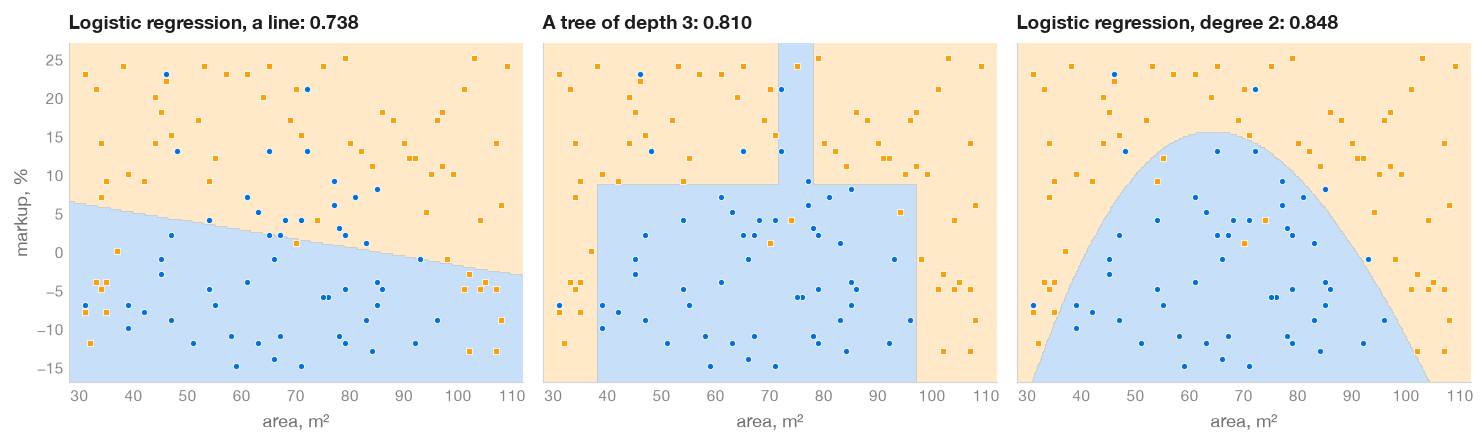

In [22]:
def area_model(degree):
    """Week 4's model: standardise, all products up to the degree, standardise, logistic regression."""
    return make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LogisticRegression(C=1e6, tol=1e-10, max_iter=1_000_000),
    )


rivals = {
    "Logistic regression, a line": area_model(1).fit(X_flats, y_flats),
    "A tree of depth 3": DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_flats, y_flats),
    "Logistic regression, degree 2": area_model(2).fit(X_flats, y_flats),
}
print(f"{'model':30s} {'accuracy, 120 flats':>20s} {'accuracy, 400 new flats':>24s}")
for name, model in rivals.items():
    print(
        f"{name:30s} {model.score(X_flats, y_flats):20.3f} {model.score(X_flats_new, y_flats_new):24.3f}"
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (name, model) in zip(axes, rivals.items(), strict=True):
    plot_regions(ax, model, f"{name}: {model.score(X_flats_new, y_flats_new):.3f}")
axes[0].set_ylabel("markup, %")
fig.tight_layout()
plt.show()

The titles show the accuracy on the 400 new flats. One straight line gets 0.738. The tree of depth 3 gets 0.810 with six rectangles. The degree 2 model gets 0.848: the data was generated with a smooth curved boundary, a parabola in the area, and this model has the right shape for it, while a tree can only follow a curve in steps.

## 3. A regression tree

A tree can also predict a number. The data is the curve of week 3: 80 flats with the distance to the city centre in km and the price per m² in US dollars, and 200 new flats to test on. The prices were generated from a parabola, $1750 - 150x + 6.2x^2$, plus noise with a standard deviation of 70.

In [23]:
def curve_truth(x):
    """The price per m² that generated the data, without the noise."""
    return 1750 - 150 * x + 6.2 * x**2


def curve_sample(seed, n, sd=70):
    """n flats: the distance to the centre in km (sorted) and the price per m² in US dollars."""
    rng = np.random.default_rng(seed)
    x = np.round(np.sort(rng.uniform(0.5, 14, n)), 1)
    y = np.round(curve_truth(x) + rng.normal(0, sd, n))
    return x, y


x_curve, y_curve = curve_sample(7, 80)  # the 80 flats we train on
x_curve_new, y_curve_new = curve_sample(999, 200)  # 200 new flats
X_curve, X_curve_new = x_curve[:, None], x_curve_new[:, None]  # scikit-learn wants a matrix

print(f"{len(x_curve)} flats, from {x_curve.min()} to {x_curve.max()} km")
print(
    f"mean price {y_curve.mean():,.1f}, standard deviation {y_curve.std():.1f}, "
    f"MSE around the mean {y_curve.var():,.0f}"
)

80 flats, from 0.6 to 13.9 km
mean price 1,074.5, standard deviation 262.1, MSE around the mean 68,714


A leaf of a regression tree predicts the mean price of its flats. The impurity of a group is the mean squared error around that mean, which is the variance of its prices. With no question at all the tree says 1,074.5 for every flat and the MSE is 68,714. A good cut leaves two groups whose prices are close together.

**Exercise 3.1.** Write `best_cut(x, y)`. Try every midpoint between neighbouring distinct values of `x`. For each one compute the weighted variance of the two groups, $(n_L \, \text{var}_L + n_R \, \text{var}_R) / n$, where `group.var()` is the variance of a group. Return the best threshold and its weighted variance as a tuple.

In [24]:
def best_cut(x, y):
    """The threshold on x with the smallest weighted variance of y: (threshold, MSE after)."""
    best = None
    values = np.unique(x)
    for t in (values[:-1] + values[1:]) / 2:  # the midpoints between neighbours
        left, right = y[x <= t], y[x > t]
        after = (len(left) * left.var() + len(right) * right.var()) / len(y)
        if best is None or after < best[1]:
            best = (float(t), float(after))
    return best

best first cut: 5.45 km
  up to 5.45 km: 29 flats, mean price 1,374.6
  beyond 5.45 km: 51 flats, mean price 903.9
MSE before the cut 68,714, after 17,521


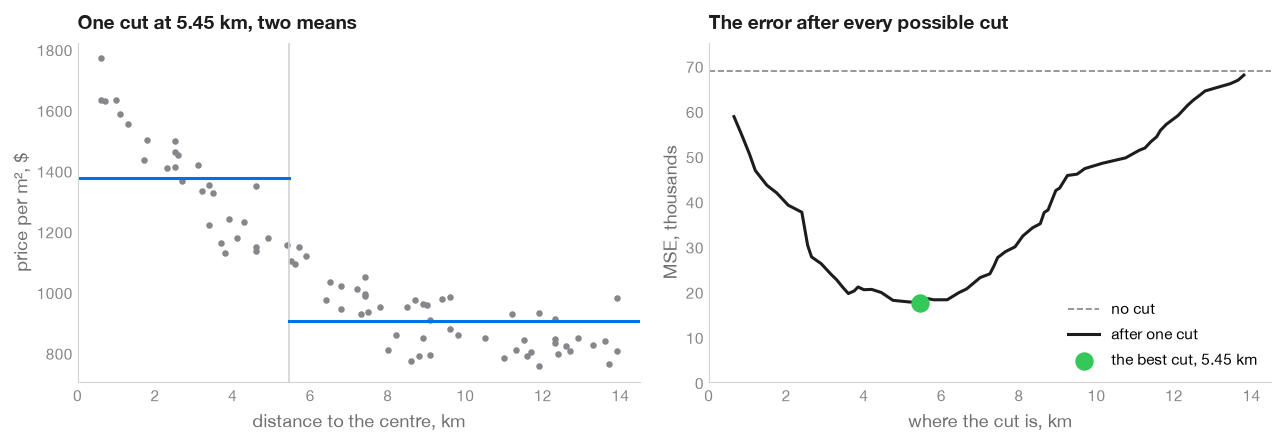

In [25]:
first_cut = best_cut(x_curve, y_curve)
assert first_cut is not None, "Fill in best_cut above"
assert np.isclose(first_cut[0], 5.45), "Expect the cut at 5.45 km: the smallest weighted variance"
assert np.isclose(
    first_cut[1], 17521, atol=1
), "Expect an MSE of 17,521 after the cut: (n_L * var_L + n_R * var_R) / n"
cut = first_cut[0]
near, far_out = y_curve[x_curve <= cut], y_curve[x_curve > cut]
print(f"best first cut: {cut} km")
print(f"  up to {cut} km: {len(near)} flats, mean price {near.mean():,.1f}")
print(f"  beyond {cut} km: {len(far_out)} flats, mean price {far_out.mean():,.1f}")
print(f"MSE before the cut {y_curve.var():,.0f}, after {first_cut[1]:,.0f}")

values = np.unique(x_curve)
thresholds = (values[:-1] + values[1:]) / 2
after = [
    (
        np.sum(x_curve <= t) * y_curve[x_curve <= t].var()
        + np.sum(x_curve > t) * y_curve[x_curve > t].var()
    )
    / len(y_curve)
    for t in thresholds
]
fig, (ax_data, ax_mse) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_data.scatter(x_curve, y_curve, s=22, color=INK3, linewidth=0)
ax_data.axvline(cut, color=LINE, lw=1.2)
ax_data.plot([0, cut], [near.mean()] * 2, color=ACCENT)
ax_data.plot([cut, 14.5], [far_out.mean()] * 2, color=ACCENT)
ax_data.set(
    xlabel="distance to the centre, km",
    ylabel="price per m², $",
    xlim=(0, 14.5),
    title=f"One cut at {cut} km, two means",
)
ax_mse.axhline(y_curve.var() / 1000, color=INK3, ls="--", lw=1.2, label="no cut")
ax_mse.plot(thresholds, np.array(after) / 1000, color=INK, label="after one cut")
ax_mse.scatter(
    [cut], [first_cut[1] / 1000], s=150, color=GREEN, zorder=4, label=f"the best cut, {cut} km"
)
ax_mse.set(
    xlabel="where the cut is, km",
    ylabel="MSE, thousands",
    xlim=(0, 14.5),
    ylim=(0, 75),
    title="The error after every possible cut",
)
ax_mse.legend(loc="lower right")
fig.tight_layout()
plt.show()

The best first cut is at 5.45 km. The 29 flats closer to the centre have a mean price of 1,374.6 and the 51 flats further out have 903.9. The MSE falls from 68,714 to 17,521. `DecisionTreeRegressor` starts with this cut and then repeats the search inside each group.

**Exercise 3.2.** For every depth in `REG_DEPTHS` fit `DecisionTreeRegressor(max_depth=depth, random_state=0)` on `X_curve`, `y_curve` and store it in `reg_trees[depth]`. Append its RMSE on the 80 training flats to `rmse_train` and on the 200 new flats to `rmse_new`. The helper `rmse(prediction, target)` is in the setup.

In [26]:
REG_DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8, None]  # None is the full tree
reg_trees, rmse_train, rmse_new = {}, [], []
for depth in REG_DEPTHS:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_curve, y_curve)
    reg_trees[depth] = tree
    rmse_train.append(rmse(tree.predict(X_curve), y_curve))
    rmse_new.append(rmse(tree.predict(X_curve_new), y_curve_new))

max_depth  leaves  RMSE, 80 flats  RMSE, 200 new flats
        1       2           132.4                129.6
        2       4            79.8                 91.7
        3       8            57.0                 83.3
        4      16            52.0                 82.3
        5      28            48.3                 81.8
        6      38            46.7                 81.9
        7      44            44.8                 83.0
        8      50            42.8                 84.1
     full      64            36.8                 83.2
a straight line, RMSE on the 200 new flats: 102.9
a parabola, RMSE on the 200 new flats: 74.1
the noise in the prices: 70


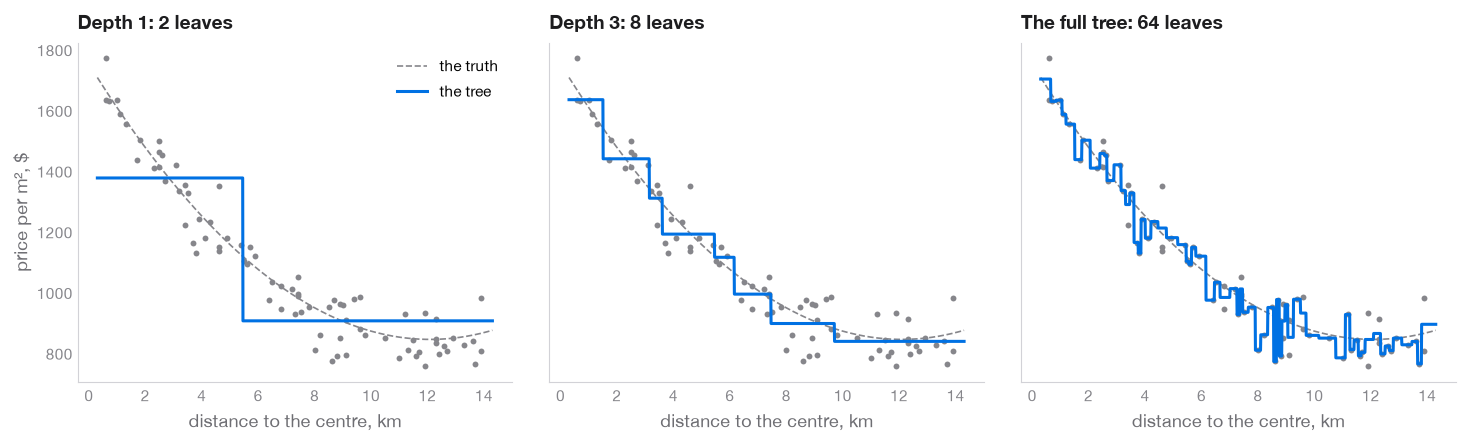

In [27]:
assert len(reg_trees) == len(REG_DEPTHS) and len(rmse_train) == len(
    REG_DEPTHS
), "Fill in the loop above: one tree and one pair of errors per depth"
assert len(rmse_new) == len(REG_DEPTHS), "Fill in the loop above: one number per depth in rmse_new"
assert all(
    isinstance(tree, DecisionTreeRegressor) for tree in reg_trees.values()
), "Every value of reg_trees is a fitted DecisionTreeRegressor"
assert np.allclose(
    rmse_train, [132.4, 79.8, 57.0, 52.0, 48.3, 46.7, 44.8, 42.8, 36.8], atol=0.06
), "Expect 132.4 at depth 1 and 36.8 for the full tree in rmse_train: predict X_curve"
assert np.allclose(
    rmse_new, [129.6, 91.7, 83.3, 82.3, 81.8, 81.9, 83.0, 84.1, 83.2], atol=0.06
), "Expect 129.6 at depth 1 and 83.2 for the full tree in rmse_new: predict X_curve_new"
print(f"{'max_depth':>9s} {'leaves':>7s} {'RMSE, 80 flats':>15s} {'RMSE, 200 new flats':>20s}")
for depth, train, new in zip(REG_DEPTHS, rmse_train, rmse_new, strict=True):
    print(
        f"{'full' if depth is None else depth:>9} {reg_trees[depth].get_n_leaves():7d} "
        f"{train:15.1f} {new:20.1f}"
    )
for degree, name in [(1, "a straight line"), (2, "a parabola")]:
    fitted = np.polyfit(x_curve, y_curve, degree)  # least squares, as in week 2
    print(
        f"{name}, RMSE on the 200 new flats: {rmse(np.polyval(fitted, x_curve_new), y_curve_new):.1f}"
    )
print("the noise in the prices: 70")

km = np.linspace(0.3, 14.3, 1401)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, depth in zip(axes, [1, 3, None], strict=True):
    tree = reg_trees[depth]
    ax.scatter(x_curve, y_curve, s=18, color=INK3, linewidth=0)
    ax.plot(km, curve_truth(km), color=INK3, ls="--", lw=1.2, label="the truth")
    ax.plot(km, tree.predict(km[:, None]), color=ACCENT, label="the tree")
    name = "The full tree" if depth is None else f"Depth {depth}"
    ax.set(xlabel="distance to the centre, km", title=f"{name}: {tree.get_n_leaves()} leaves")
axes[0].set_ylabel("price per m², $")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

The prediction is a staircase, and every step is the mean price of the training flats above it. The full tree has 64 leaves, one for each distinct distance in the data, and its steps follow the noise. On the new flats the error hardly moves after depth 3: it stays between 81.8 and 84.1, and the full tree has 83.2. The parabola gets 74.1, close to the noise level of 70. A staircase needs many steps to follow a smooth curve, and every step needs flats to average over. The page `04_regression_tree.html` has the depth as a slider.

**Exercise 3.3.** The largest distance among the training flats is 13.9 km. Ask the tree of depth 3 for the price at 16, 20 and 25 km: store `reg_trees[3].predict(far)` in `tree_far`.

In [28]:
far = np.array([[16.0], [20.0], [25.0]])  # km from the centre, beyond every training flat
tree_far = reg_trees[3].predict(far)

distance, km   the truth   tree of depth 3   fitted parabola
          16         937               836               936
          20       1,230               836             1,249
          25       1,875               836             1,933
the last leaf: 22 training flats from 9.8 to 13.9 km, mean price 836.3


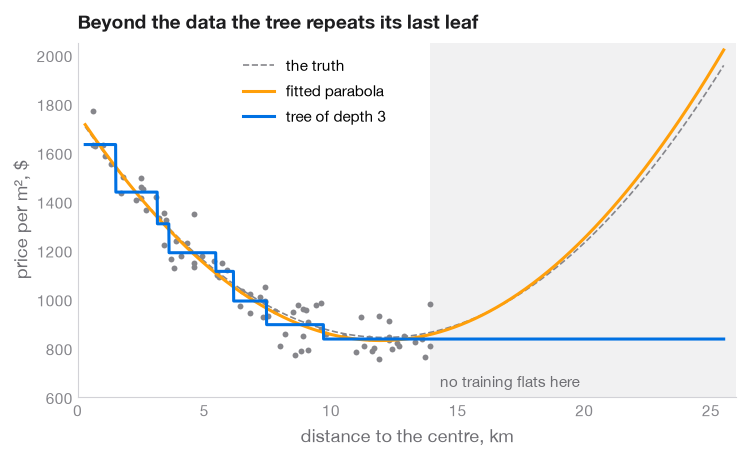

In [29]:
assert len(reg_trees) == len(REG_DEPTHS), "Finish Exercise 3.2 first"
assert tree_far is not None, "Fill in tree_far above"
assert np.allclose(
    tree_far, 836.3, atol=0.05
), "Expect 836.3 three times: reg_trees[3].predict(far)"
parabola = np.polyfit(x_curve, y_curve, 2)
print("distance, km   the truth   tree of depth 3   fitted parabola")
for distance, tree_says in zip(far[:, 0], tree_far, strict=True):
    print(
        f"{distance:12.0f} {curve_truth(distance):11,.0f} {tree_says:17,.0f} "
        f"{np.polyval(parabola, distance):17,.0f}"
    )
last_leaf = reg_trees[3].apply(X_curve) == reg_trees[3].apply(far)[0]  # the flats in the same leaf
print(
    f"the last leaf: {last_leaf.sum()} training flats from {x_curve[last_leaf].min()} to "
    f"{x_curve[last_leaf].max()} km, mean price {y_curve[last_leaf].mean():.1f}"
)

km = np.linspace(0.3, 25.5, 2521)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.axvspan(x_curve.max(), 26, color=LINE, alpha=0.3, linewidth=0)
ax.scatter(x_curve, y_curve, s=18, color=INK3, linewidth=0)
ax.plot(km, curve_truth(km), color=INK3, ls="--", lw=1.2, label="the truth")
ax.plot(km, np.polyval(parabola, km), color=ORANGE, label="fitted parabola")
ax.plot(km, reg_trees[3].predict(km[:, None]), color=ACCENT, label="tree of depth 3")
ax.text(14.3, 640, "no training flats here", fontsize=11, color=INK2)
ax.set(
    xlabel="distance to the centre, km",
    ylabel="price per m², $",
    xlim=(0, 26),
    ylim=(600, 2050),
    title="Beyond the data the tree repeats its last leaf",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.36, 1.0))
plt.show()

The tree says 836 three times. Its last leaf holds the 22 training flats beyond 9.7 km, and every distance past the data falls into that leaf. The truth climbs to 1,230 at 20 km. The fitted parabola says 1,249 there, because the data was generated from a parabola. A tree cannot extrapolate: outside the range of the training data it repeats the mean of the nearest leaf.

## 4. Fake listings: a tree against logistic regression

The data is the fake listings of week 5: 2,000 listings to train on and 4,000 to test on, 5% of them fakes. The features are the markup in percent, the number of photos and the age of the seller's account in months. The metric is average precision, as in weeks 5 and 6. Fakes are rare, so accuracy says little, and the moderators read a list ranked by the predicted probability.

In [30]:
FAKE_FEATURES = ["markup", "photos", "age"]


def fake_sample(seed, n, share=0.05):
    """n listings: X = (markup in %, number of photos, account age in months), y = 1 for a fake."""
    rng = np.random.default_rng(seed)
    y = np.zeros(n, dtype=int)
    y[: int(round(share * n))] = 1  # exactly this share of fakes
    rng.shuffle(y)
    markup = np.round(np.where(y == 1, rng.normal(-12, 11, n), rng.normal(4, 9, n)))
    photos = np.where(y == 1, rng.poisson(5, n), rng.poisson(9, n)) + 1
    age = np.round(np.where(y == 1, rng.exponential(8, n), rng.exponential(30, n)) + 1)
    return np.column_stack([markup, photos, age]).astype(float), y


def make_logreg():
    """Logistic regression without a penalty on standardised features, as in week 5."""
    return make_pipeline(
        StandardScaler(), LogisticRegression(C=np.inf, tol=1e-10, max_iter=1_000_000)
    )


X_fake, y_fake = fake_sample(1, 2000)  # the listings we train on
X_fake_test, y_fake_test = fake_sample(5001, 4000)  # the test set

print(
    f"train: {len(y_fake)} listings, {y_fake.sum()} fakes; "
    f"test: {len(y_fake_test)} listings, {y_fake_test.sum()} fakes"
)
print(f"accuracy of flagging nothing on the test listings: {np.mean(y_fake_test == 0):.2f}")

train: 2000 listings, 100 fakes; test: 4000 listings, 200 fakes
accuracy of flagging nothing on the test listings: 0.95


**Exercise 4.1.** Choose the depth by cross-validation. Build `fake_search`: a `GridSearchCV` over `DecisionTreeClassifier(random_state=0)` with the grid `{"max_depth": FAKE_DEPTHS}`, `cv=folds` and `scoring="average_precision"`, fitted on `X_fake`, `y_fake`.

In [31]:
FAKE_DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, None]  # None is the full tree
fake_search = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    {"max_depth": FAKE_DEPTHS},
    cv=folds,
    scoring="average_precision",
).fit(X_fake, y_fake)

In [32]:
assert fake_search is not None, "Fill in fake_search above"
fake_cv = fake_search.cv_results_["mean_test_score"]
assert np.allclose(
    fake_cv, [0.259, 0.362, 0.420, 0.472, 0.517, 0.453, 0.394, 0.328, 0.263], atol=0.001
), (
    "Expect 0.259 at depth 1 and 0.517 at depth 5: scoring='average_precision', cv=folds, "
    "fitted on X_fake, y_fake"
)
fake_depth = fake_search.best_params_["max_depth"]
print(
    f"{'max_depth':>9s} {'leaves':>7s} {'leaves of one class':>20s} {'cross-validated average precision':>34s}"
)
for depth, cv in zip(FAKE_DEPTHS, fake_cv, strict=True):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_fake, y_fake)
    pure = np.sum(tree.tree_.impurity[tree.tree_.children_left == -1] == 0)  # leaves with Gini 0
    print(f"{'full' if depth is None else depth:>9} {tree.get_n_leaves():7d} {pure:20d} {cv:34.3f}")
print(f"depth chosen by cross-validation: {fake_depth}")

max_depth  leaves  leaves of one class  cross-validated average precision
        1       2                    0                              0.259
        2       4                    0                              0.362
        3       8                    1                              0.420
        4      15                    4                              0.472
        5      26                   10                              0.517
        6      42                   27                              0.453
        8      72                   57                              0.394
       10      98                   88                              0.328
     full     119                  114                              0.263
depth chosen by cross-validation: 5


Cross-validation picks depth 5, with an average precision of 0.517. Deeper trees rank the listings worse, and the full tree falls to 0.263. A tree ranks by the share of fakes in the leaf, and 114 of the 119 leaves of the full tree hold one class, so it answers 0 or 1 for almost every listing and has little left to rank by.

**Exercise 4.2.** Now open the test set. Fit a tree of depth 5 on the 2,000 training listings as `fake_tree` and store its probabilities of "fake" for the test listings in `p_tree`. Fit `make_logreg()` on the same listings and store its probabilities in `p_lr`.

In [33]:
fake_tree = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_fake, y_fake)
p_tree = fake_tree.predict_proba(X_fake_test)[:, 1]
p_lr = make_logreg().fit(X_fake, y_fake).predict_proba(X_fake_test)[:, 1]

4,000 test listings   average precision  ROC-AUC  flagged  precision  recall  different probabilities
tree of depth 5                   0.615    0.934      150      0.733   0.550                       18
logistic regression               0.752    0.971      154      0.773   0.595                     3653


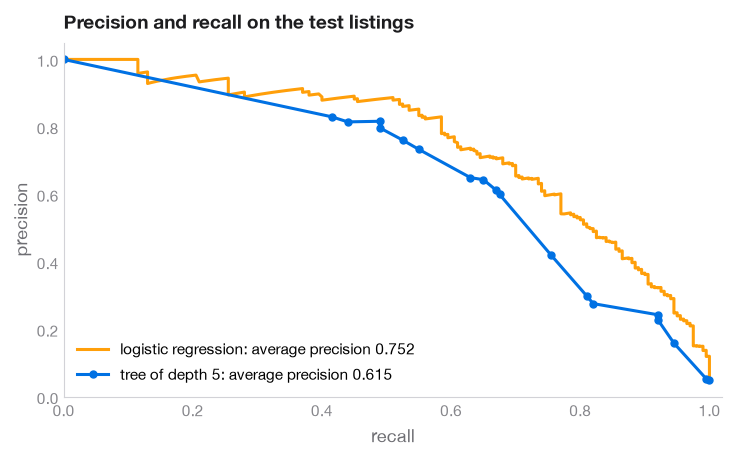

In [34]:
assert (
    fake_tree is not None and p_tree is not None and p_lr is not None
), "Fill in fake_tree, p_tree and p_lr above"
assert np.isclose(average_precision_score(y_fake_test, p_tree), 0.615, atol=0.001), (
    "Expect an average precision of 0.615 for the tree: max_depth=5, random_state=0, "
    "predict_proba(X_fake_test)[:, 1]"
)
assert np.isclose(
    average_precision_score(y_fake_test, p_lr), 0.752, atol=0.001
), "Expect an average precision of 0.752 for logistic regression: use make_logreg()"
print(
    f"{'4,000 test listings':20s} {'average precision':>18s} {'ROC-AUC':>8s} {'flagged':>8s} {'precision':>10s} "
    f"{'recall':>7s} {'different probabilities':>24s}"
)
for name, p in [(f"tree of depth {fake_tree.get_depth()}", p_tree), ("logistic regression", p_lr)]:
    tp, fp, fn, tn = confusion(y_fake_test, p >= 0.5)
    print(
        f"{name:20s} {average_precision_score(y_fake_test, p):18.3f} {roc_auc_score(y_fake_test, p):8.3f} "
        f"{tp + fp:8d} {tp / (tp + fp):10.3f} {tp / (tp + fn):7.3f} {len(np.unique(p)):24d}"
    )

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for name, p, colour in [("logistic regression", p_lr, ORANGE), ("tree of depth 5", p_tree, ACCENT)]:
    precision, recall, _ = precision_recall_curve(y_fake_test, p)
    ax.plot(
        recall,
        precision,
        "o-" if p is p_tree else "-",
        ms=5,
        color=colour,
        label=f"{name}: average precision {average_precision_score(y_fake_test, p):.3f}",
    )
ax.set(
    xlabel="recall",
    ylabel="precision",
    xlim=(0, 1.02),
    ylim=(0, 1.05),
    title="Precision and recall on the test listings",
)
ax.legend(loc="lower left")
plt.show()

On the test listings the tree has an average precision of 0.615 and logistic regression has 0.752. At the threshold 0.5 the two are closer: the tree flags 150 listings with a precision of 0.733 and a recall of 0.550, and logistic regression flags 154 with 0.773 and 0.595. The gap is in the ranking. The tree has 26 leaves and gives only 18 different probabilities to the 4,000 listings, so its curve is a handful of points and many listings share a score. Logistic regression gives almost every listing its own score. In this data the chance of a fake changes smoothly with every feature, which suits a linear model, as the curved boundary suited the degree 2 model in section 2.

### 4.1 Does the scale of a feature matter?

kNN in week 1 needed the features on a common scale. To see what a tree needs, rescale two columns: multiply the markup by 1,000 and the number of photos by 0.01.

In [35]:
SCALE = np.array([1000.0, 0.01, 1.0])  # markup, photos, age
X_fake_scaled, X_fake_test_scaled = X_fake * SCALE, X_fake_test * SCALE
scaler = StandardScaler().fit(X_fake)


def make_knn():
    """kNN with k = 41, the value that cross-validation chose in week 6. No scaling inside."""
    return KNeighborsClassifier(n_neighbors=41)


versions = {  # the name of a version: (training listings, test listings)
    "standardised": (scaler.transform(X_fake), scaler.transform(X_fake_test)),
    "original columns": (X_fake, X_fake_test),
    "markup x 1,000, photos x 0.01": (X_fake_scaled, X_fake_test_scaled),
}
print(f"{'standard deviation of':30s} " + " ".join(f"{name:>9s}" for name in FAKE_FEATURES))
for name, (train, _) in versions.items():
    print(f"{name:30s} " + " ".join(f"{value:9.2f}" for value in train.std(axis=0)))

standard deviation of             markup    photos       age
standardised                        1.00      1.00      1.00
original columns                    9.76      3.16     29.24
markup x 1,000, photos x 0.01    9763.98      0.03     29.24


**Exercise 4.3.** Fit a tree of depth 5 on the rescaled training listings as `scaled_tree` and store its probabilities for the rescaled test listings in `p_tree_scaled`. Then, for each version of the data in `versions`, fit `make_knn()` on the training listings and store its average precision on the test listings in `knn_ap` under the name of the version.

In [36]:
scaled_tree = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_fake_scaled, y_fake)
p_tree_scaled = scaled_tree.predict_proba(X_fake_test_scaled)[:, 1]
knn_ap = {}
for name, (train, test) in versions.items():
    knn = make_knn().fit(train, y_fake)
    knn_ap[name] = average_precision_score(y_fake_test, knn.predict_proba(test)[:, 1])

In [37]:
assert p_tree is not None, "Finish Exercise 4.2 first"
assert (
    scaled_tree is not None and p_tree_scaled is not None and len(knn_ap) == 3
), "Fill in scaled_tree, p_tree_scaled and knn_ap above"
assert np.array_equal(p_tree_scaled, p_tree), (
    "The probabilities must equal those of Exercise 4.2: max_depth=5, random_state=0, fitted on "
    "X_fake_scaled and asked about X_fake_test_scaled"
)
assert np.allclose(
    [knn_ap[name] for name in versions], [0.723, 0.686, 0.496], atol=0.001
), "Expect 0.723, 0.686 and 0.496 for kNN: make_knn().fit(train, y_fake), predict_proba(test)[:, 1]"
print(
    f"root question of the tree: markup <= {fake_tree.tree_.threshold[0]:g}, "
    f"after the rescaling: markup <= {scaled_tree.tree_.threshold[0]:g}"
)
print(
    f"test listings where the two trees give different probabilities: "
    f"{np.sum(p_tree_scaled != p_tree)}"
)
print(f"\n{'kNN, k = 41':30s} average precision on the test listings")
for name, value in knn_ap.items():
    print(f"{name:30s} {value:.3f}")

root question of the tree: markup <= -15.5, after the rescaling: markup <= -15500
test listings where the two trees give different probabilities: 0

kNN, k = 41                    average precision on the test listings
standardised                   0.723
original columns               0.686
markup x 1,000, photos x 0.01  0.496


The tree gives the same probability to every one of the 4,000 test listings. Its root question "markup $\le -15.5$" became "markup $\le -15500$", and the groups stayed the same. A tree compares one feature with a threshold at a time, so only the order of the values inside a column matters. kNN adds the columns up inside a distance. It gets 0.723 on standardised features, 0.686 on the original columns, and 0.496 after the rescaling, when the distance is almost all markup. So kNN needs its features on a common scale and a tree does not. The second part of the page `05_unstable_trees.html` shows the same table.

## 5. The same data, a different tree

How much does a tree depend on the exact flats it was trained on? One dataset is enough to find out: resample it. A bootstrap resample draws 120 flats from the 120 with replacement, so some flats come up twice or more and some are left out.

**Exercise 5.1.** Draw 200 resamples of the flats of section 2 and fit a full tree on each. The loop below draws the row numbers `idx`. Inside it, fit `DecisionTreeClassifier(random_state=0)` on `X_flats[idx]`, `y_flats[idx]` and append the tree to `boot_trees`. After the loop fill `boot_pred`, an array with one row per tree that holds its predictions for the 400 new flats, and `boot_acc`, the accuracy of every tree on the new flats.

In [38]:
rng = np.random.default_rng(0)
boot_trees = []
for _ in range(200):
    idx = rng.integers(0, 120, 120)  # 120 row numbers between 0 and 119, with replacement
    boot_trees.append(DecisionTreeClassifier(random_state=0).fit(X_flats[idx], y_flats[idx]))
boot_pred = np.array([tree.predict(X_flats_new) for tree in boot_trees])  # 200 rows, 400 columns
boot_acc = np.mean(boot_pred == y_flats_new, axis=1)

accuracy on the 400 new flats
  the first ten trees: 0.790 0.823 0.760 0.787 0.757 0.755 0.807 0.805 0.807 0.815
  all 200 trees: mean 0.787, smallest 0.740, largest 0.830
  the full tree on the original 120 flats: 0.780
the root asks about the markup in 94% of the trees, about the area in 6%
the root question of the first five trees: markup <= 13.5, markup <= 4.5, markup <= 9.5, markup <= 8, markup <= 6
a resampled tree disagrees with the original tree on 10.9% of the new flats, on average


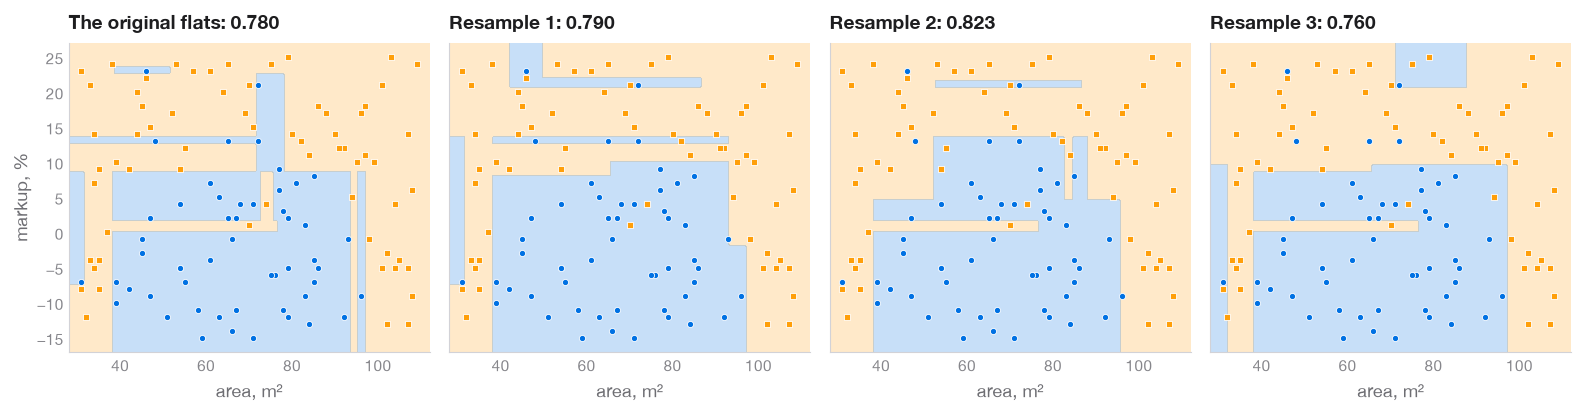

In [39]:
assert (
    len(boot_trees) == 200 and boot_pred is not None and boot_acc is not None
), "Fill in boot_trees, boot_pred and boot_acc above"
boot_pred, boot_acc = np.asarray(boot_pred), np.asarray(boot_acc)
assert boot_pred.shape == (
    200,
    400,
), "Expect one row per tree and one column per new flat: (200, 400)"
assert np.allclose(boot_acc[:3], [0.79, 0.8225, 0.76]), (
    "Expect 0.790, 0.823 and 0.760 for the first three trees: fit on X_flats[idx], y_flats[idx] "
    "with random_state=0, predict X_flats_new"
)
full_tree = DecisionTreeClassifier(random_state=0).fit(X_flats, y_flats)  # on the original flats
full_pred = full_tree.predict(X_flats_new)
print("accuracy on the 400 new flats")
print("  the first ten trees: " + " ".join(f"{value:.3f}" for value in boot_acc[:10]))
print(
    f"  all 200 trees: mean {boot_acc.mean():.3f}, smallest {boot_acc.min():.3f}, "
    f"largest {boot_acc.max():.3f}"
)
print(f"  the full tree on the original 120 flats: {np.mean(full_pred == y_flats_new):.3f}")
root_feature = np.array([FLAT_FEATURES[tree.tree_.feature[0]] for tree in boot_trees])
root_threshold = np.array([tree.tree_.threshold[0] for tree in boot_trees])
print(
    f"the root asks about the markup in {np.mean(root_feature == 'markup'):.0%} of the trees, "
    f"about the area in {np.mean(root_feature == 'area'):.0%}"
)
print(
    "the root question of the first five trees: "
    + ", ".join(
        f"{name} <= {t:g}" for name, t in zip(root_feature[:5], root_threshold[:5], strict=True)
    )
)
print(
    f"a resampled tree disagrees with the original tree on {np.mean(boot_pred != full_pred):.1%} "
    f"of the new flats, on average"
)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
plot_regions(axes[0], full_tree, f"The original flats: {np.mean(full_pred == y_flats_new):.3f}")
for number, ax in enumerate(axes[1:]):
    plot_regions(ax, boot_trees[number], f"Resample {number + 1}: {boot_acc[number]:.3f}")
axes[0].set_ylabel("markup, %")
fig.tight_layout()
plt.show()

The 200 trees were grown from resamples of the same 120 flats, and their accuracy on the new flats ranges from 0.740 to 0.830, with a mean of 0.787. The plot shows the regions of the original tree and of the first three resampled trees, with the accuracy on the new flats in the title. The regions move from one resample to the next. Even the first question changes: the root asks about the markup in 94% of the trees and about the area in 6%. A resampled tree disagrees with the tree grown on the original flats on 10.9% of the new flats, on average. This is the variance of week 3. A full tree fits its sample closely, and it fits the noise of the sample too.

**Exercise 5.2.** Let the 200 trees vote. Store in `vote_share` the share of the trees that say "sold" for every new flat, in `vote` the answer of the majority (1 when the share is at least 0.5, otherwise 0) and in `vote_acc` the accuracy of `vote` on the new flats.

In [40]:
vote_share = boot_pred.mean(axis=0)  # one number per new flat
vote = (vote_share >= 0.5).astype(int)
vote_acc = np.mean(vote == y_flats_new)

trees in the vote   accuracy on the 400 new flats
                1                           0.790
                5                           0.797
               25                           0.805
              100                           0.810
              200                           0.807
a single tree, on average: 0.787; single trees that beat the vote of 200: 27
new flats where the 200 trees are not unanimous: 70.8%
new flats where the vote is between 20% and 80%: 18.5%


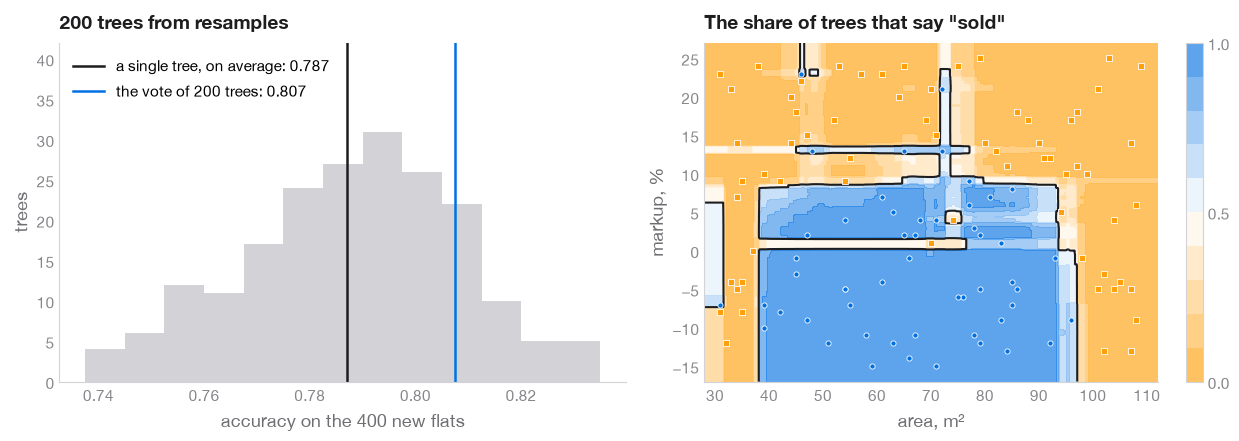

In [41]:
assert len(boot_trees) == 200 and boot_pred is not None, "Finish Exercise 5.1 first"
assert (
    vote_share is not None and vote is not None and vote_acc is not None
), "Fill in vote_share, vote and vote_acc above"
assert np.shape(vote_share) == (400,), "Expect one share per new flat: boot_pred.mean(axis=0)"
assert np.isclose(vote_acc, 0.8075), "Expect 0.807: the majority is vote_share >= 0.5"
print("trees in the vote   accuracy on the 400 new flats")
for n_trees in [1, 5, 25, 100, 200]:
    first = (boot_pred[:n_trees].mean(axis=0) >= 0.5).astype(int)
    print(f"{n_trees:17d} {np.mean(first == y_flats_new):31.3f}")
print(
    f"a single tree, on average: {boot_acc.mean():.3f}; "
    f"single trees that beat the vote of 200: {np.sum(boot_acc > vote_acc)}"
)
print(
    f"new flats where the 200 trees are not unanimous: {np.mean((vote_share > 0) & (vote_share < 1)):.1%}"
)
print(
    f"new flats where the vote is between 20% and 80%: "
    f"{np.mean((vote_share > 0.2) & (vote_share < 0.8)):.1%}"
)

grid_share = np.mean([tree.predict(GRID) for tree in boot_trees], axis=0).reshape(AREA_GRID.shape)
fig, (ax_hist, ax_vote) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_hist.hist(boot_acc, bins=np.arange(0.7375, 0.84, 0.0075), color=LINE)
ax_hist.axvline(
    boot_acc.mean(), color=INK, lw=1.8, label=f"a single tree, on average: {boot_acc.mean():.3f}"
)
ax_hist.axvline(vote_acc, color=ACCENT, lw=1.8, label=f"the vote of 200 trees: {vote_acc:.3f}")
ax_hist.set(
    xlabel="accuracy on the 400 new flats",
    ylabel="trees",
    ylim=(0, 42),
    title="200 trees from resamples",
)
ax_hist.legend(loc="upper left")
shade = ax_vote.contourf(
    AREA_GRID, MARKUP_GRID, grid_share, levels=np.linspace(0, 1, 11), cmap=SHARE_CMAP, alpha=0.7
)
ax_vote.contour(AREA_GRID, MARKUP_GRID, grid_share, levels=[0.5], colors=INK, linewidths=1.5)
scatter_sold(ax_vote, X_flats, y_flats, size=14)
ax_vote.set(xlabel="area, m²", ylabel="markup, %", title='The share of trees that say "sold"')
fig.colorbar(shade, ax=ax_vote, ticks=[0, 0.5, 1])
fig.tight_layout()
plt.show()

The vote of the 200 trees gets 0.807 of the new flats right. A single tree gets 0.787 on average, the full tree on the original flats gets 0.780, and 27 of the 200 single trees beat the vote. In the picture on the right the colour is strong where the trees agree and pale where they argue, and the black line is the boundary of the vote. The trees are not unanimous on 70.8% of the new flats, yet on only 18.5% is the vote between 20% and 80%: on most flats only a few trees disagree with the rest. One tree is shaky, and many trees together are steadier. The next lecture builds on this: bagging and the random forest grow many trees on resamples and let them vote. The first part of the page `05_unstable_trees.html` draws the resamples one by one.

## 6. Bonus: a tree from scratch

This section is optional, and nothing else depends on it.

One recursive function grows a tree. It finds the best question for its group with `best_split` from Exercise 1.3, splits the group in two and calls itself on each half with one level of depth less. It stops when the group holds one class, when the depth limit is reached, or when no question can split the group.

**Exercise 6.1 (bonus).** Write `fit_tree(X, y, max_depth)`. It returns the tree as nested dictionaries. Every node has `"counts"`, the number of rows of class 0 and of class 1 in its group, and `"label"`, the majority class. A node with a question also has `"feature"` (the number of the column), `"threshold"`, `"left"` (the node for the rows with feature $\le$ threshold) and `"right"`. Then write `predict_tree(tree, X)`: for every row of `X` follow the questions down to a leaf and return the labels as an array.

In [42]:
def fit_tree(X, y, max_depth):
    """Grow a tree of at most max_depth levels of questions; nested dictionaries."""
    counts = np.bincount(y, minlength=2)
    node = {"counts": counts, "label": int(np.argmax(counts))}
    if max_depth == 0 or counts.max() == len(y):  # deep enough, or one class
        return node
    split = best_split(X, y)
    if split is None:  # all rows have the same features: nothing to ask
        return node
    j, t, _ = split
    yes = X[:, j] <= t
    node["feature"], node["threshold"] = j, t
    node["left"] = fit_tree(X[yes], y[yes], max_depth - 1)
    node["right"] = fit_tree(X[~yes], y[~yes], max_depth - 1)
    return node


def predict_tree(tree, X):
    """The label of the leaf that every row of X lands in."""
    labels = []
    for row in X:
        node = tree
        while "feature" in node:  # a node with a question: go left or right
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        labels.append(node["label"])
    return np.array(labels)

In [43]:
assert best_split(X_hand, y_hand) is not None, "Finish Exercise 1.3 first"
my_tree = fit_tree(X_flats, y_flats, 3)
assert my_tree is not None, "Fill in fit_tree above"
my_pred_new = predict_tree(my_tree, X_flats_new)
assert my_pred_new is not None, "Fill in predict_tree above"
sk_tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_flats, y_flats)
assert my_tree["feature"] == 1 and np.isclose(
    my_tree["threshold"], 8.5
), "Expect the root question markup <= 8.5: column 1 and the threshold 8.5 from best_split"
my_pred_train = predict_tree(my_tree, X_flats)
assert np.array_equal(
    my_pred_train, sk_tree.predict(X_flats)
), "The answers on the 120 training flats differ from scikit-learn's tree of depth 3"
assert np.array_equal(
    my_pred_new, sk_tree.predict(X_flats_new)
), "The answers on the 400 new flats differ from scikit-learn's tree of depth 3"


def show_tree(node, indent=""):
    """Print a tree of nested dictionaries in the layout of export_text."""
    if "feature" not in node:
        print(
            f"{indent}|--- class: {node['label']}   (not sold {node['counts'][0]}, sold {node['counts'][1]})"
        )
        return
    name = FLAT_FEATURES[node["feature"]]
    print(f"{indent}|--- {name} <= {node['threshold']:.2f}")
    show_tree(node["left"], indent + "|   ")
    print(f"{indent}|--- {name} >  {node['threshold']:.2f}")
    show_tree(node["right"], indent + "|   ")


show_tree(my_tree)
print(f"\naccuracy on the 120 training flats: {np.mean(my_pred_train == y_flats):.3f}")
print(f"accuracy on the 400 new flats:      {np.mean(my_pred_new == y_flats_new):.3f}")
print(
    f"new flats where scikit-learn's tree of depth 3 answers differently: "
    f"{np.sum(my_pred_new != sk_tree.predict(X_flats_new))}"
)

|--- markup <= 8.50
|   |--- area <= 97.00
|   |   |--- area <= 38.00
|   |   |   |--- class: 0   (not sold 8, sold 1)
|   |   |--- area >  38.00
|   |   |   |--- class: 1   (not sold 3, sold 45)
|   |--- area >  97.00
|   |   |--- class: 0   (not sold 11, sold 0)
|--- markup >  8.50
|   |--- area <= 78.00
|   |   |--- area <= 71.50
|   |   |   |--- class: 0   (not sold 25, sold 3)
|   |   |--- area >  71.50
|   |   |   |--- class: 1   (not sold 1, sold 3)
|   |--- area >  78.00
|   |   |--- class: 0   (not sold 20, sold 0)

accuracy on the 120 training flats: 0.933
accuracy on the 400 new flats:      0.810
new flats where scikit-learn's tree of depth 3 answers differently: 0


The tree written from scratch is the tree of depth 3 from section 2: the same questions, the same answer for every one of the 400 new flats, 0.933 on the training flats and 0.810 on the new ones.

For deeper trees the two can differ in a detail. Further down, a group of two flats can be split equally well by the area and by the markup. Our search keeps the first of two equally good questions. scikit-learn tries the features in a shuffled order at every node, so it may keep the other one, and `random_state=0` fixes the shuffling. On resampled data such ties are common, which is why section 5 uses scikit-learn's trees throughout.

## 7. What to remember

- A decision tree asks questions of the form "feature $\le$ threshold". A leaf answers with the majority class of its training rows, or with their mean for regression, and the share of a class in the leaf is the predicted probability.
- A tree is grown greedily from the top. Every feature and every midpoint is tried, the question with the smallest weighted impurity is kept, and the search repeats inside each group. The impurity is Gini or entropy for classes and the variance for numbers.
- A full tree fits the training data almost perfectly and does worse on new data. Limit it with `max_depth` or `min_samples_leaf` and choose the value by cross-validation.
- The prediction of a tree is piecewise constant: rectangles on a plane, a staircase on a line. Outside the range of the training data it repeats the nearest leaf.
- A tree needs no scaling, since only the order of the values in a column matters. Its probabilities are coarse: one value per leaf.
- A tree is unstable. A resample of the same data gives a different tree, and the vote of many such trees is steadier than one tree.

## Try at home

1. In section 1, change the label of listing 4 (markup $-14$) to fake and run `best_split` again. Which question wins now, and what is its weighted Gini?
2. In section 2, grow the trees with `criterion="entropy"`. Is the tree of depth 3 the same? Does cross-validation still pick depth 3?
3. In section 2, search over `max_leaf_nodes` from 2 to 22 with `GridSearchCV`. How many leaves does cross-validation choose, and how does that tree do on the 400 new flats?
4. In section 5, repeat the resampling with trees of depth 3 in place of full trees. Is the spread of the accuracy smaller? Does the vote still beat a single tree?